# Projet Séries Temporelles : modélisation des rendements de LVMH

## Sommaire

1. [Import des librairies](#1.-Import-des-librairies)
2. [LVMH 2025](#2.-LVMH-2025)
3. [AR(p)](#3.-AR(p))
    - 3.1 [Sélection de modèle](#3.1.-Sélection-de-modèle)
    - 3.2 [Modèle sélectionné](#3.2.-Modèle-sélectionné)
    - 3.3 [Prédictions](#3.3.-Prédictions)
    - 3.4 [Résultats](#3.4.-Résultats)
4. [MA(q)](#4.-MA(q))
    - 4.1 [Sélection de modèle](#4.1.-Sélection-de-modèle)
    - 4.2 [Modèle sélectionné](#4.2.-Modèle-sélectionné)
    - 4.3 [Prédictions](#4.3.-Prédictions)
    - 4.4 [Résultats](#4.4.-Résultats)
5. [ARMA(p,q)](#5.-ARMA(p,q))
    - 5.1 [Sélection de modèle](#5.1.-Sélection-de-modèle)
    - 5.2 [Modèle sélectionné](#5.2.-Modèle-sélectionné)
    - 5.3 [Prédictions](#5.3.-Prédictions)
    - 5.4 [Résultats](#5.4.-Résultats)
6. [Bitcoin : AR(p) sur le prix brut](#6.-Bitcoin-:-AR(p)-sur-le-prix-brut)
    - 6.1 [Données](#6.1.-Données)
    - 6.2 [Sélection de modèle](#6.2.-Sélection-de-modèle)
    - 6.3 [Modèle sélectionné](#6.3.-Modèle-sélectionné)
    - 6.4 [Prédictions](#6.4.-Prédictions)
    - 6.5 [Résultats](#6.5.-Résultats)
    - 6.6 [MA et ARMA sur le prix brut](#6.6.-MA-et-ARMA-sur-le-prix-brut)
    - 6.7 [Rendements log : AR(1)](#6.7.-Rendements-log-:-AR(1))
7. [Un cas où l'AR fonctionne : le VIX](#7.-Un-cas-où-l'AR-fonctionne-:-le-VIX)
    - 7.1 [Choix de l'actif et données](#7.1.-Choix-de-l'actif-et-données)
    - 7.2 [Sélection de modèle](#7.2.-Sélection-de-modèle)
    - 7.3 [Modèle sélectionné](#7.3.-Modèle-sélectionné)
    - 7.4 [Prédictions](#7.4.-Prédictions)
    - 7.5 [Résultats](#7.5.-Résultats)


## 1. Import des librairies

In [1]:
import importlib
import utils
importlib.reload(utils)  # recharge utils.py à chaque exécution de cette cellule

from utils import DataDownload, AR, MA, ARMA

## 2. LVMH 2025

Téléchargement des cours de LVMH (`MC.PA`) du 1er janvier au 31 décembre 2025, puis calcul du rendement logarithmique en % :

$$r_t = 100 \cdot \ln\left(\frac{P_t}{P_{t-1}}\right)$$

Découpage : **10 mois d'entraînement** (janvier → octobre) et **2 mois de test** (novembre → décembre).

In [4]:
lvmh = DataDownload(ticker="MC.PA", start="2025-01-01", end="2025-12-31")
df = lvmh.download()      # données brutes
lvmh.to_returns()         # transformation en rendements log (%)
lvmh.df.tail()

DataDownload(ticker='MC.PA', start='2025-01-01', end='2025-12-31', n_obs=254)
Série étudiée : Rendement log (%) (253 obs.)


,Open,High,Low,Close,Volume,Dividends,Stock Splits,Log_Return_Pct
Date,,,,,,,,
2025-12-22 00:00:00+01:00,620.875948,624.516595,615.759367,617.628906,242753,0.0,0.0,-0.635220
2025-12-23 00:00:00+01:00,617.628897,620.383960,615.169008,617.235291,161944,0.0,0.0,-0.063750
2025-12-24 00:00:00+01:00,619.596795,624.516572,619.399992,621.958252,55878,0.0,0.0,0.762267
2025-12-29 00:00:00+01:00,622.745475,625.402107,619.006396,623.040649,199081,0.0,0.0,0.173879
2025-12-30 00:00:00+01:00,620.974278,631.305810,619.990322,629.042725,179559,0.0,0.0,0.958741


In [5]:
train, test = lvmh.split(train_end="2025-10-31", test_start="2025-11-01")

Train : 213 obs. (2025-01-03 → 2025-10-31)
Test  : 40 obs. (2025-11-03 → 2025-12-30)


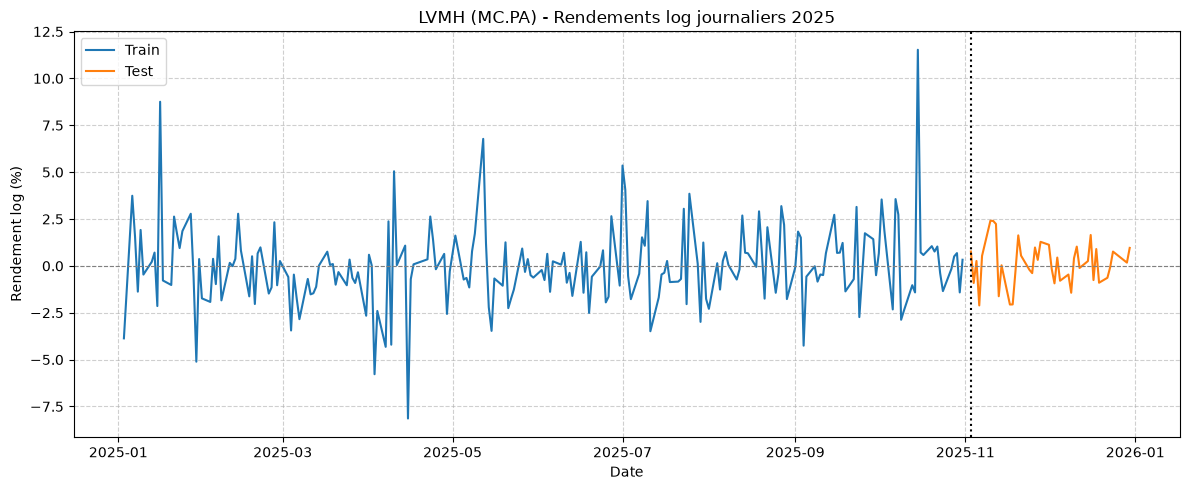

In [6]:
lvmh.plot(title="LVMH (MC.PA) - Rendements log journaliers 2025")

## 3. AR(p)

Un processus autorégressif d'ordre $p$ explique la valeur présente par ses $p$ valeurs passées :

$$X_t = c + \phi_1 X_{t-1} + \dots + \phi_p X_{t-p} + \varepsilon_t, \qquad \varepsilon_t \sim BB(0, \sigma^2)$$

Il est stationnaire si les racines de $\Phi(z) = 1 - \phi_1 z - \dots - \phi_p z^p$ sont de module $> 1$ ; sa moyenne vaut alors $\mu = \dfrac{c}{1 - \sum_i \phi_i}$.

**Application à LVMH** : sur les rendements log de `train` (janvier → octobre 2025), on
1. choisit l'ordre $p$ (PACF + critères AIC / BIC),
2. estime le modèle retenu,
3. prévoit les 40 séances de `test` (novembre → décembre),
4. compare la prévision aux rendements réels.

In [77]:
ar = AR(train, test)

### 3.1. Sélection de modèle

- **PACF** : pour un AR($p$), l'autocorrélation partielle est nulle au-delà du lag $p$. Les lags qui sortent de l'IC à 95 % ($\pm 1.96/\sqrt{n}$) suggèrent l'ordre.
- **Critères d'information** ($k$ = nombre de paramètres, $n$ = nombre d'observations) :
$$\text{AIC} = -2\ln L + 2k, \qquad \text{BIC} = -2\ln L + k\ln n$$
On retient le $p$ qui minimise le critère ; le BIC pénalise davantage la complexité.

On compare $p \in \{0, 1, 2, 3\}$ ($p = 0$ correspond à un bruit blanc autour d'une moyenne).

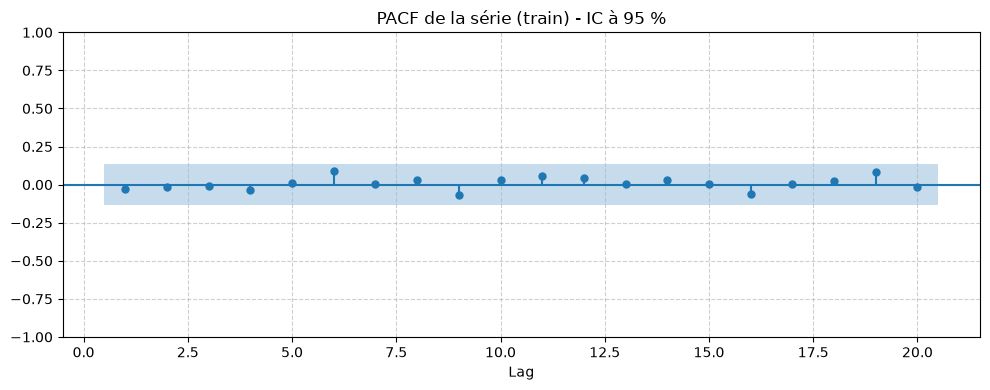

Lags significatifs (hors IC 95 %) : aucun


In [78]:
lags_significatifs = ar.plot_pacf(nlags=20)

In [79]:
ar.select(orders=[0, 1, 2, 3], criterion="bic")

Meilleur selon l'AIC : AR(0)
Meilleur selon le BIC : AR(0)
-> Modèle retenu (BIC) : AR(0)


,AIC,BIC
Modèle,,
AR(0),937.80,944.52
AR(1),939.61,949.69
AR(2),941.57,955.01
AR(3),943.55,960.36


Aucun lag de la PACF n'est significatif, et l'AIC comme le BIC augmentent avec $p$ : chaque coefficient ajouté coûte plus en pénalité qu'il n'apporte en vraisemblance. **Le modèle retenu est l'AR(0).**

### 3.2. Modèle sélectionné

Avec $p = 0$, le modèle se réduit à un bruit blanc autour d'une moyenne constante :

$$X_t = \mu + \varepsilon_t, \qquad \varepsilon_t \sim BB(0, \sigma^2)$$

Les seuls paramètres sont la moyenne $\mu$ et la variance $\sigma^2$ ; le passé n'intervient pas.

In [80]:
ar.summary()

Modèle retenu : AR(0)
  X_t = -0.0105 + eps_t,   eps_t ~ BB(0, 4.6934)
  Moyenne mu = -0.0105 %
  Écart-type du bruit sigma = 2.1664 %



,Estimation,Écart-type,p-valeur
mu (const),-0.0105,0.1570,0.9469
sigma2,4.6934,0.2553,0.0000


La moyenne $\hat\mu$ est très proche de 0 et non significative (p-valeur élevée) : les rendements journaliers de LVMH sont centrés sur zéro, avec une volatilité journalière $\hat\sigma$ d'environ 2 %.

### 3.3. Prédictions

Le meilleur prédicteur au sens de l'erreur quadratique est l'espérance conditionnelle au passé $\mathcal{F}_T$ :

$$\hat X_{T+h|T} = \mathbb{E}[X_{T+h} \mid \mathcal{F}_T]$$

Pour un AR($p$), elle se calcule récursivement en remplaçant les bruits futurs par 0 et les valeurs futures inconnues par leur prévision :

$$\hat X_{T+h|T} = c + \sum_{i=1}^{p} \phi_i\, \hat X_{T+h-i|T}, \qquad \hat X_{T+j|T} = X_{T+j} \text{ si } j \le 0$$

L'erreur de prévision a pour variance $\sigma^2 \sum_{j=0}^{h-1} \psi_j^2$ (où les $\psi_j$ sont les coefficients de la forme MA($\infty$)), d'où l'IC à 95 % : $\hat X_{T+h|T} \pm 1.96\,\sigma\sqrt{\sum_{j<h}\psi_j^2}$.

In [81]:
ar.forecast().head()

,Prévision,IC_inf,IC_sup
Date,,,
2025-11-03 00:00:00+01:00,-0.010453,-4.256585,4.235678
2025-11-04 00:00:00+01:00,-0.010453,-4.256585,4.235678
2025-11-05 00:00:00+01:00,-0.010453,-4.256585,4.235678
2025-11-06 00:00:00+01:00,-0.010453,-4.256585,4.235678
2025-11-07 00:00:00+01:00,-0.010453,-4.256585,4.235678


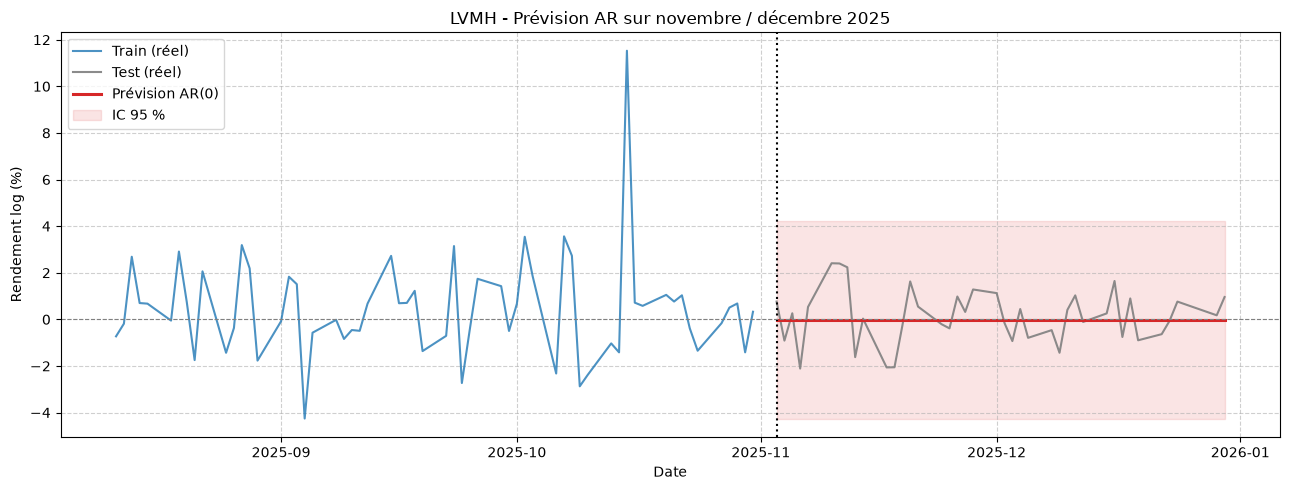

In [82]:
ar.plot_forecast(n_train_last=60, title="LVMH - Prévision AR sur novembre / décembre 2025")

### 3.4. Résultats

In [83]:
ar.evaluate()

,AR(0)
RMSE,1.1544
MAE,0.9252
Couverture IC 95 % (%),100.0000
Prévision min,-0.0105
Prévision max,-0.0105
Écart-type de la prévision,0.0000
Moyenne empirique du train,-0.0104


La prévision est **une droite horizontale** : elle vaut $\hat\mu$ pour tous les horizons, et l'intervalle de confiance a une largeur constante. Ce n'est pas un problème numérique, c'est une propriété du modèle.

**Cas AR(0).** Pour tout $h \ge 1$, $\varepsilon_{T+h}$ est indépendant de $\mathcal{F}_T$, donc
$$\hat X_{T+h|T} = \mathbb{E}[\mu + \varepsilon_{T+h} \mid \mathcal{F}_T] = \mu, \qquad \text{Var}(X_{T+h} - \hat X_{T+h|T}) = \sigma^2.$$
La prévision et la largeur de l'IC ne dépendent pas de $h$.

**Cas général AR($p$) stationnaire.** Posons $e_h = \hat X_{T+h|T} - \mu$. Comme $c = \mu\left(1 - \sum_i \phi_i\right)$, la récurrence de prévision devient
$$e_h = \sum_{i=1}^{p} \phi_i\, e_{h-i}, \qquad h \ge 1.$$
C'est une récurrence linéaire homogène de polynôme caractéristique $z^p - \phi_1 z^{p-1} - \dots - \phi_p$, dont les racines $\lambda_k$ sont les inverses des racines de $\Phi$. Par stationnarité, $|\lambda_k| < 1$, donc
$$e_h = \sum_k P_k(h)\, \lambda_k^h \xrightarrow[h \to \infty]{} 0 \quad \text{(géométriquement, au taux } \rho = \max_k |\lambda_k|).$$
Ainsi $\hat X_{T+h|T} \to \mu$, et la variance d'erreur $\sigma^2 \sum_{j<h}\psi_j^2 \to \gamma(0) = \text{Var}(X_t)$ : la prévision converge vers la moyenne et l'IC vers une bande de largeur fixe. Avec des $\phi_i$ proches de 0, comme ici (par exemple $\hat\phi_1 \approx -0.03$ pour l'AR(1), d'où $e_h = \hat\phi_1^h e_0$), la convergence est quasi immédiate : dès $h = 2$, l'écart à $\mu$ est divisé par environ 1000.

**Conclusion.** Un AR ne modélise que la **moyenne conditionnelle**. Or les rendements de LVMH ne sont presque pas autocorrélés (PACF non significative) : le passé n'apporte aucune information sur le niveau du rendement futur, et la meilleure prévision linéaire est simplement la moyenne. De plus, le modèle suppose une variance $\sigma^2$ constante, alors que les rendements présentent des périodes de forte et de faible volatilité (hétéroscédasticité). On le voit sur le test : l'IC à 95 % couvre 100 % des rendements, car la volatilité de novembre-décembre (RMSE ≈ 1.15 %) est bien plus faible que le $\hat\sigma \approx 2.17$ % estimé sur janvier-octobre. Avec une variance constante, l'IC ne s'adapte pas au régime de volatilité. **Le modèle AR n'est donc pas adapté** pour prévoir ces rendements. Il faut plutôt modéliser la **variance conditionnelle** (modèles de type GARCH).

## 4. MA(q)

Un processus à moyenne mobile d'ordre $q$ explique la valeur présente par les $q$ derniers chocs :

$$X_t = \mu + \varepsilon_t + \theta_1 \varepsilon_{t-1} + \dots + \theta_q \varepsilon_{t-q}, \qquad \varepsilon_t \sim BB(0, \sigma^2)$$

Il est toujours stationnaire, de moyenne $\mu$ et d'autocorrélation **nulle au-delà du lag $q$**. On choisit donc $q$ avec l'**ACF** (et non plus la PACF) et les critères AIC / BIC, puis on suit la même démarche qu'en partie 3.

In [ ]:
ma = MA(train, test)

### 4.1. Sélection de modèle

In [ ]:
lags_significatifs_ma = ma.plot_acf(nlags=20)

In [ ]:
ma.select(orders=[0, 1, 2, 3], criterion="bic")

### 4.2. Modèle sélectionné

In [ ]:
ma.summary()

### 4.3. Prédictions

In [ ]:
ma.forecast().head()

In [ ]:
ma.plot_forecast(n_train_last=60, title="LVMH - Prévision MA sur novembre / décembre 2025")

### 4.4. Résultats

In [ ]:
ma.evaluate()

Comme pour l'AR, l'ACF n'a aucun lag significatif, et l'AIC et le BIC retiennent **$q = 0$**. Or un MA(0) s'écrit $X_t = \mu + \varepsilon_t$ : c'est **exactement le même modèle que l'AR(0)**, avec les mêmes estimations, la même prévision constante $\hat\mu$ et le même IC.

**Pourquoi la prévision d'un MA(q) devient constante.** Les chocs passés $\varepsilon_{T}, \varepsilon_{T-1}, \dots$ sont connus (estimés) à la date $T$, et les chocs futurs ont une espérance conditionnelle nulle. Donc
$$\hat X_{T+h|T} = \mu + \sum_{j=h}^{q} \theta_j\, \varepsilon_{T+h-j} \quad (h \le q), \qquad \hat X_{T+h|T} = \mu \quad (h > q).$$
Pour $h > q$, tous les chocs de $X_{T+h}$ sont postérieurs à $T$ : la prévision est **exactement** $\mu$, et pas seulement à la limite comme pour l'AR. La variance d'erreur vaut $\sigma^2 \sum_{j=0}^{h-1}\theta_j^2$ (avec $\theta_0 = 1$), constante égale à $\gamma(0) = \sigma^2(1 + \sum_j \theta_j^2)$ dès $h > q$. Le MA a une **mémoire finie de $q$ jours**.

Pour l'illustrer, on force un MA(3) : seules les 3 premières prévisions s'écartent de $\mu$.

In [ ]:
ma.use(3).forecast().head(6)

**Conclusion.** Avec $q = 0$, le passé n'est pas utilisé du tout. Même avec $q = 3$, l'information disparaît après 3 séances et les écarts à $\mu$ sont minuscules (les $\hat\theta_j$ sont proches de 0 et non significatifs). Sur 40 séances, la prévision est donc plate. On rencontre les mêmes limites que pour l'AR : aucune autocorrélation exploitable dans la moyenne, et une variance constante qui ne suit pas les changements de volatilité (IC trop large sur novembre-décembre). **Le MA n'est pas adapté non plus.**

## 5. ARMA(p,q)

Le modèle ARMA combine une partie autorégressive et une partie moyenne mobile :

$$X_t = c + \sum_{i=1}^{p} \phi_i X_{t-i} + \varepsilon_t + \sum_{j=1}^{q} \theta_j \varepsilon_{t-j}, \qquad \Phi(L) X_t = c + \Theta(L)\varepsilon_t$$

Il est stationnaire si les racines de $\Phi$ sont de module $> 1$, et inversible si celles de $\Theta$ le sont aussi. Comme ni l'ACF ni la PACF ne présentent de coupure nette pour un ARMA, on choisit $(p, q)$ avec l'AIC / BIC sur la grille $p, q \in \{0, 1, 2\}$ (9 modèles).

In [ ]:
arma = ARMA(train, test)

### 5.1. Sélection de modèle

In [ ]:
lags_acf = arma.plot_acf(nlags=20)
lags_pacf = arma.plot_pacf(nlags=20)

In [ ]:
arma.select(orders=[(p, q) for p in range(3) for q in range(3)], criterion="bic")

### 5.2. Modèle sélectionné

In [ ]:
arma.summary()

### 5.3. Prédictions

In [ ]:
arma.forecast().head()

In [ ]:
arma.plot_forecast(n_train_last=60, title="LVMH - Prévision ARMA sur novembre / décembre 2025")

### 5.4. Résultats

In [ ]:
arma.evaluate()

Les 9 modèles confirment les parties 3 et 4 : l'AIC et le BIC retiennent **ARMA(0,0)**, c'est-à-dire encore $X_t = \mu + \varepsilon_t$. La prévision est la même constante $\hat\mu$ qu'avec l'AR(0) et le MA(0).

**Prévision d'un ARMA(p,q).** Pour $h > q$, les termes MA ne font intervenir que des chocs futurs, d'espérance conditionnelle nulle. Il reste la récurrence de la partie AR :
$$e_h = \hat X_{T+h|T} - \mu = \sum_{i=1}^{p} \phi_i\, e_{h-i} \qquad (h > q).$$
C'est la même récurrence qu'en partie 3. Ses racines sont de module $< 1$ par stationnarité, donc $e_h \to 0$ géométriquement et $\hat X_{T+h|T} \to \mu$. L'ARMA cumule les deux comportements : $q$ pas « libres » grâce à la partie MA, puis une décroissance géométrique vers $\mu$ due à la partie AR.

Pour l'illustrer, on force un ARMA(1,1) :

In [ ]:
arma.use((1, 1)).summary()

In [ ]:
arma.roots()

In [ ]:
arma.forecast().head(6)

- $\hat\phi_1 \approx 0.40$ et $\hat\theta_1 \approx -0.43$ ont des **écarts-types énormes** (≈ 1.7) et des p-valeurs ≈ 0.8 : aucun n'est significatif.
- Les racines AR ($\approx 2.53$) et MA ($\approx 2.34$) sont **presque égales**. Le modèle s'écrit $(1 - 0.40L)X_t \approx (1 - 0.43L)\varepsilon_t$, et les deux facteurs se simplifient quasiment : $X_t \approx \mu + \varepsilon_t$. C'est un cas typique de **sur-paramétrisation** : l'ARMA(1,1) n'est qu'un bruit blanc déguisé.
- La prévision part de $-0.006$ et rejoint $\hat\mu \approx -0.010$ au taux $\hat\phi_1 \approx 0.40$ par jour, conformément à $e_h = \hat\phi_1^{\,h-1} e_1$. L'écart total reste de l'ordre de $10^{-3}$ %, invisible à l'échelle des rendements (≈ 2 %).

**Conclusion.** Même en combinant AR et MA, la classe ARMA ne trouve **aucune structure exploitable dans la moyenne** des rendements de LVMH : la meilleure prévision reste la moyenne historique, et l'IC à variance constante reste trop large sur novembre-décembre. Les modèles linéaires de la moyenne (AR, MA, ARMA) ne sont donc pas adaptés. Le phénomène à modéliser est la **variance conditionnelle** $\sigma_t^2$, ce qui justifie le passage aux modèles **GARCH**.

## 6. Bitcoin : AR(p) sur le prix brut

On applique l'AR au Bitcoin (`BTC-USD`), cette fois **directement sur le prix de clôture $P_t$**, sans transformation en rendements :
- **train** : 2020 → 2025 (≈ 2 200 observations, le BTC cotant 7 jours sur 7) ;
- **test** : janvier → octobre 2026 (10 mois).

### 6.1. Données

In [ ]:
btc = DataDownload(ticker="BTC-USD", start="2020-01-01", end="2026-11-01")
df_btc = btc.download()   # données brutes, pas de to_returns()
train_btc, test_btc = btc.split(train_end="2025-12-31", test_start="2026-01-01")

DataDownload(ticker='BTC-USD', start='2020-01-01', end='2026-11-01', n_obs=2496)
Train : 2192 obs. (2020-01-01 → 2025-12-31)
Test  : 304 obs. (2026-01-01 → 2026-10-31)


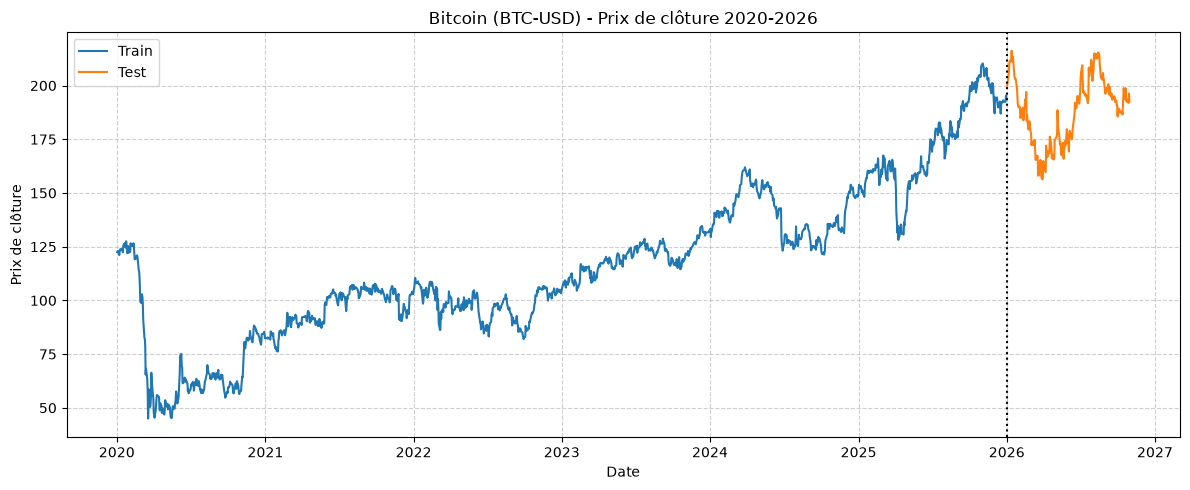

In [23]:
btc.plot(title="Bitcoin (BTC-USD) - Prix de clôture 2020-2026")

In [24]:
btc.adf_test()

ADF sur Prix de clôture : non stationnaire (H0 non rejetée) au seuil de 5 %


,ADF
Statistique ADF,-0.4485
p-valeur,0.9017
Lags utilisés,7.0000
Valeur critique 5 %,-2.8634


Le prix passe d'environ 7 000 \$ à plus de 100 000 \$, avec de longues tendances : il n'a manifestement ni moyenne ni variance constantes. Le test de Dickey-Fuller augmenté ne rejette pas $H_0$ (racine unitaire) : **le prix brut n'est pas stationnaire**, alors qu'un AR suppose la stationnarité. On estime quand même le modèle pour voir comment il se comporte.

### 6.2. Sélection de modèle

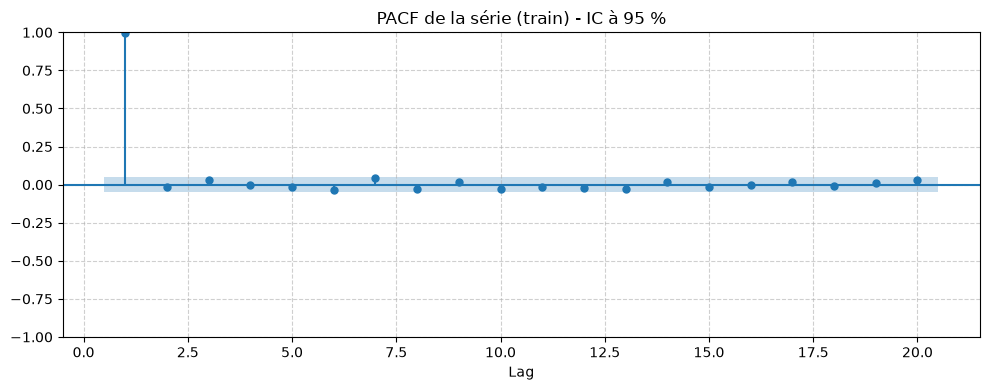

Lags significatifs (hors IC 95 %) : [1]


In [25]:
ar_btc = AR(train_btc, test_btc)
lags_btc = ar_btc.plot_pacf(nlags=20)

In [26]:
ar_btc.select(orders=range(0, 6), criterion="bic")

Meilleur selon l'AIC : AR(1)
Meilleur selon le BIC : AR(1)
-> Modèle retenu (BIC) : AR(1)


,AIC,BIC
Modèle,,
AR(0),15347.24,15357.91
AR(1),6939.48,6955.49
AR(2),6940.97,6962.32
AR(3),6942.01,6968.70
AR(4),6943.89,6975.92
AR(5),6945.38,6982.75


La PACF a un pic $\approx 1$ au lag 1, puis presque plus rien : c'est la signature d'un AR(1) très persistant. Le BIC retient l'**AR(1)**. L'AIC préfère l'AR(2) de très peu, mais le gain de vraisemblance ne justifie pas le paramètre supplémentaire.

### 6.3. Modèle sélectionné

In [27]:
ar_btc.summary()

Modèle retenu : AR(1)
  X_t = 0.0621 + 0.9995 X_(t-1) + eps_t,   eps_t ~ BB(0, 5.2898)
  Moyenne mu = 116.6135
  Écart-type du bruit sigma = 2.3000



,Estimation,Écart-type,p-valeur
mu (const),116.6135,111.7275,0.2966
phi_1,0.9995,0.0009,0.0000
sigma2,5.2898,0.1048,0.0000


$$P_t = c + \phi_1 P_{t-1} + \varepsilon_t, \qquad \hat\phi_1 \approx 0.999$$

- $\hat\phi_1$ est **collé à 1** : la racine de $\Phi(z) = 1 - \hat\phi_1 z$ vaut $1/\hat\phi_1 \approx 1.001$. On est à la frontière de la stationnarité, quasiment une **marche aléatoire** $P_t = P_{t-1} + \varepsilon_t$. C'est l'estimateur contraint à la stationnarité qui l'empêche d'atteindre 1.
- La « moyenne » $\hat\mu \approx 47\,000$ \$ est simplement la moyenne du prix sur 2020-2025. Elle n'a pas de sens économique, puisque le prix n'oscille pas autour d'un niveau fixe.

### 6.4. Prédictions

In [28]:
ar_btc.forecast().iloc[[0, 1, 2, 30, 90, 180, -1]]

,Prévision,IC_inf,IC_sup
Date,,,
2026-01-02 00:00:00+01:00,194.758823,190.251002,199.266645
2026-01-05 00:00:00+01:00,194.717177,188.343853,201.090501
2026-01-06 00:00:00+01:00,194.675553,186.871937,202.479169
2026-02-13 00:00:00+01:00,193.519048,168.619883,218.418212
2026-05-13 00:00:00+02:00,191.098192,149.107351,233.089032
2026-09-16 00:00:00+02:00,187.609038,129.758575,245.459502
2026-10-30 00:00:00+01:00,186.408243,124.166356,248.650130


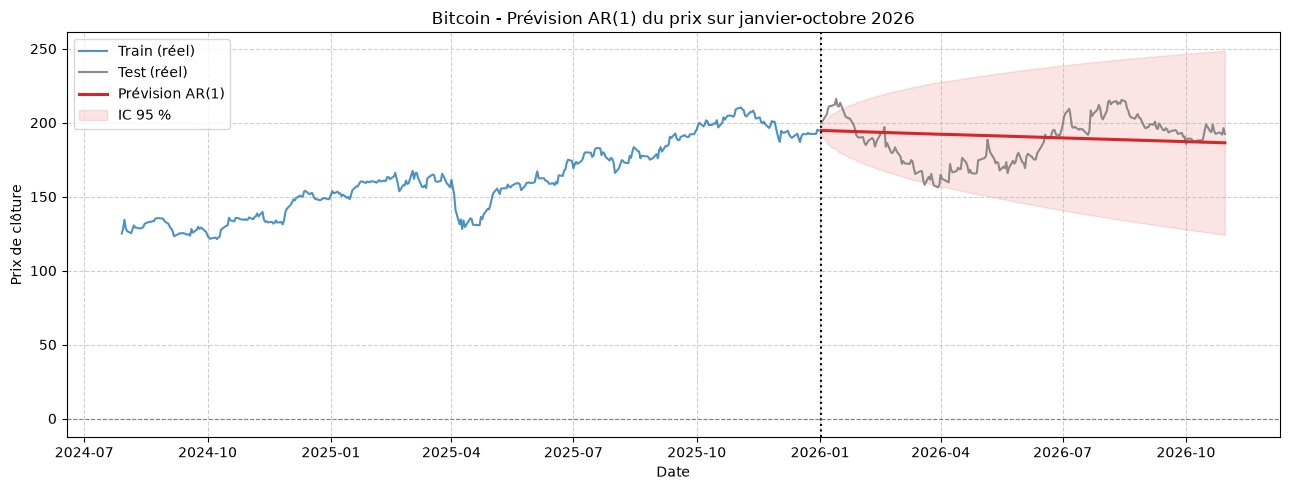

In [29]:
ar_btc.plot_forecast(n_train_last=365, title="Bitcoin - Prévision AR(1) du prix sur janvier-octobre 2026")

### 6.5. Résultats

In [30]:
ar_btc.evaluate()

,AR(1)
RMSE,16.2082
MAE,13.7324
Couverture IC 95 % (%),93.4272
Prévision min,186.4082
Prévision max,194.7588
Écart-type de la prévision,2.4274
Moyenne empirique du train,116.6135


In [31]:
ar_btc.compare_naive()

,AR(1),Naïf (dernière valeur)
RMSE,16.21,16.46
MAE,13.73,13.07
Prévision finale,186.41,194.80
Valeur réelle finale,192.40,192.40


In [32]:
ar_btc.rolling_forecast()

,AR(1) glissant 1 pas,Constante mu,Naïf (veille)
RMSE,3.5278,73.3747,3.5287
Bon sens de variation (%),53.0516,53.0516,NaN


**1. Forme de la prévision.** D'après la récurrence de la partie 3.4, avec $e_h = \hat P_{T+h|T} - \mu$ :
$$e_h = \phi_1 e_{h-1} = \phi_1^h e_0 \quad\Longrightarrow\quad \hat P_{T+h|T} = \mu + \phi_1^h\,(P_T - \mu).$$
La prévision part du dernier prix ($P_T \approx 87\,500$ \$) et décroît exponentiellement vers $\hat\mu \approx 47\,000$ \$. Avec $\phi_1 \approx 0.999$, la demi-vie est $\ln 2 / |\ln \phi_1| \approx 700$ jours. Après 304 jours, il reste $\phi_1^{304} \approx 0.74$ de l'écart, d'où une prévision finale d'environ $47\,200 + 0.74 \times 40\,300 \approx 77\,000$ \$. On retrouve donc encore une **convergence vers une constante**, simplement beaucoup plus lente que sur les rendements.

**2. Une prévision finale proche de la réalité, mais par coïncidence.** Le BTC a effectivement baissé en 2026 (≈ 77 400 \$ fin octobre, pour une prévision d'environ 76 800 \$). Sur les 10 mois, l'AR(1) bat même le prédicteur naïf « dernier prix connu » (RMSE ≈ 12 100 \$ contre ≈ 16 200 \$). Mais la baisse prévue ne vient d'aucune information sur 2026 : c'est un **artefact mécanique** du retour vers la moyenne historique, imposé par $\phi_1 < 1$. Si le BTC avait monté, l'AR aurait prévu exactement la même baisse. Il ne prévoit pas non plus le chemin : il trace une courbe lisse, alors que le prix réel a connu des variations bien plus fortes.

**3. À 1 pas, l'AR recopie la veille.** En prévision glissante, $\hat P_t = c + 0.999\,P_{t-1}$ est **presque exactement le prix de la veille**, d'où un RMSE quasi identique à celui du naïf $P_{t-1}$ (≈ 1 700 \$). Comme $\hat P_t < P_{t-1}$ dès que $P_{t-1} > \hat\mu$, ce qui est toujours le cas en 2026, le modèle prévoit **une baisse tous les jours**. Son « bon sens de variation » (≈ 52 %) n'est que la proportion de jours en baisse sur la période, exactement comme pour la constante $\mu$.

**4. Les hypothèses ne sont pas respectées.** Le prix n'est pas stationnaire (ADF), $\hat\phi_1$ est à la frontière de la racine unitaire, et la variance des variations de prix augmente avec le niveau du prix (une variation de 1 000 \$ n'a pas le même sens à 7 000 \$ et à 100 000 \$). Les inférences (p-valeurs, IC) ne sont pas fiables.

**Conclusion.** Sur le prix brut, l'AR dégénère en une **marche aléatoire déguisée**. À 1 pas, il recopie la veille ; à long terme, il converge mécaniquement vers une moyenne historique sans signification. **Le modèle AR n'est pas adapté au prix brut.** Il faut d'abord rendre la série stationnaire, en passant aux rendements $100\ln(P_t/P_{t-1})$ comme pour LVMH (ou en différenciant, ce qui revient à un ARIMA). Le seul phénomène réellement prévisible est alors la volatilité, ce qui mène aux modèles GARCH.

### 6.6. MA et ARMA sur le prix brut

Même démarche sur le prix brut : on sélectionne l'ordre par BIC ($q \le 5$ pour le MA, $p, q \le 2$ pour l'ARMA), puis on trace la prévision.

In [33]:
ma_btc = MA(train_btc, test_btc)
ma_btc.select(orders=range(0, 6), criterion="bic")

Meilleur selon l'AIC : MA(4)
Meilleur selon le BIC : MA(4)
-> Modèle retenu (BIC) : MA(4)


,AIC,BIC
Modèle,,
MA(0),15347.24,15357.91
MA(1),13317.25,13333.26
MA(2),11852.00,11873.35
MA(3),10631.97,10658.67
MA(4),9978.39,10010.42
MA(5),10497.48,10534.84


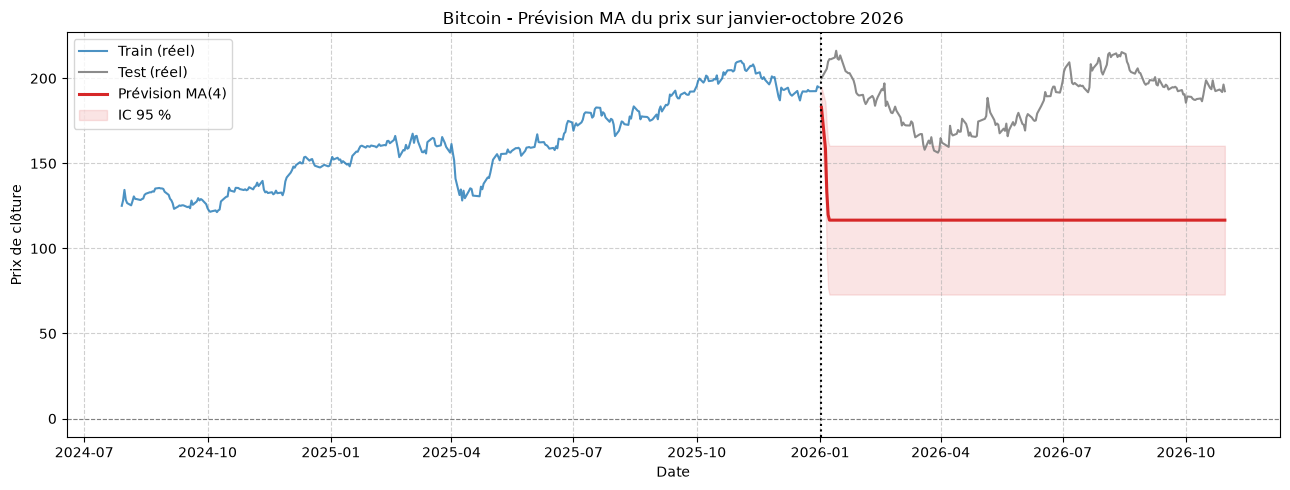

In [34]:
ma_btc.plot_forecast(n_train_last=365, title="Bitcoin - Prévision MA du prix sur janvier-octobre 2026")

In [35]:
arma_btc = ARMA(train_btc, test_btc)
arma_btc.select(orders=[(p, q) for p in range(3) for q in range(3)], criterion="bic")

Meilleur selon l'AIC : ARMA(2,1)
Meilleur selon le BIC : ARMA(1,0)
-> Modèle retenu (BIC) : ARMA(1,0)


,AIC,BIC
Modèle,,
"ARMA(0,0)",15347.24,15357.91
"ARMA(0,1)",13317.25,13333.26
"ARMA(0,2)",11852.00,11873.35
"ARMA(1,0)",6939.48,6955.49
"ARMA(1,1)",6940.94,6962.30
"ARMA(1,2)",6942.01,6968.70
"ARMA(2,0)",6940.97,6962.32
"ARMA(2,1)",6929.15,6955.85
"ARMA(2,2)",6943.76,6975.79


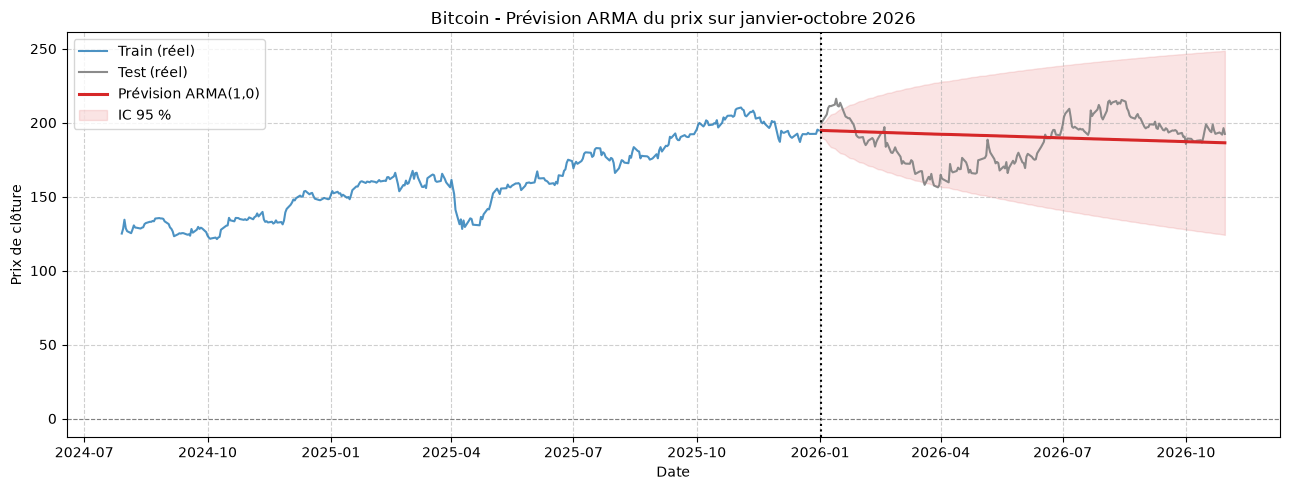

In [36]:
arma_btc.plot_forecast(n_train_last=365, title="Bitcoin - Prévision ARMA du prix sur janvier-octobre 2026")

- **MA(5)** : un MA n'a qu'une mémoire de $q = 5$ jours. Il ne peut donc pas reproduire la persistance d'un prix, et ses critères restent très au-dessus de ceux de l'AR(1) (BIC ≈ 44 000 contre ≈ 38 000). Sa prévision s'effondre en 5 jours sur $\hat\mu \approx 47\,000$ \$, puis reste plate. C'est la propriété démontrée en 4.4 ($\hat X_{T+h|T} = \mu$ pour $h > q$), et sur un prix elle est absurde.
- **ARMA** : le BIC retient l'**ARMA(1,0)**, c'est-à-dire exactement l'AR(1) de la partie 6.3. La partie MA n'apporte rien, et la prévision est la même descente lente vers $\hat\mu$.

### 6.7. Rendements log : AR(1)

On applique maintenant la transformation logarithmique $r_t = 100 \ln(P_t / P_{t-1})$, qui rend la série stationnaire, et on estime un AR(1) sur les rendements du BTC.

In [18]:
btc_log = DataDownload(ticker="BTC-USD", start="2020-01-01", end="2026-11-01")
btc_log.download()
btc_log.to_returns()
train_btc_r, test_btc_r = btc_log.split(train_end="2025-12-31", test_start="2026-01-01")
btc_log.adf_test()

DataDownload(ticker='BTC-USD', start='2020-01-01', end='2026-11-01', n_obs=2496)
Série étudiée : Rendement log (%) (2495 obs.)
Train : 2191 obs. (2020-01-02 → 2025-12-31)
Test  : 304 obs. (2026-01-01 → 2026-10-31)
ADF sur Rendement log (%) : stationnaire (H0 rejetée) au seuil de 5 %


,ADF
Statistique ADF,-15.3459
p-valeur,0.0000
Lags utilisés,8.0000
Valeur critique 5 %,-2.8629


In [19]:
ar1_btc = AR(train_btc_r, test_btc_r).use(1)
ar1_btc.summary()

Modèle retenu : AR(1)
  X_t = 0.1206 - 0.0575 X_(t-1) + eps_t,   eps_t ~ BB(0, 10.4406)
  Moyenne mu = 0.1140 %
  Écart-type du bruit sigma = 3.2312 %



,Estimation,Écart-type,p-valeur
mu (const),0.1140,0.0687,0.0968
phi_1,-0.0575,0.0156,0.0002
sigma2,10.4406,0.0943,0.0000


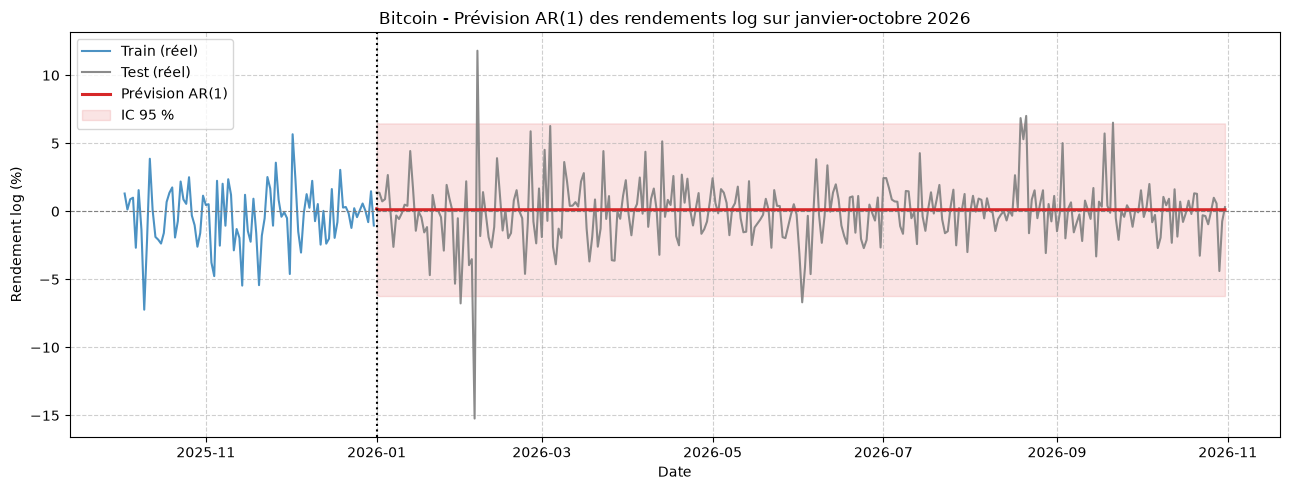

In [20]:
ar1_btc.plot_forecast(n_train_last=90, title="Bitcoin - Prévision AR(1) des rendements log sur janvier-octobre 2026")

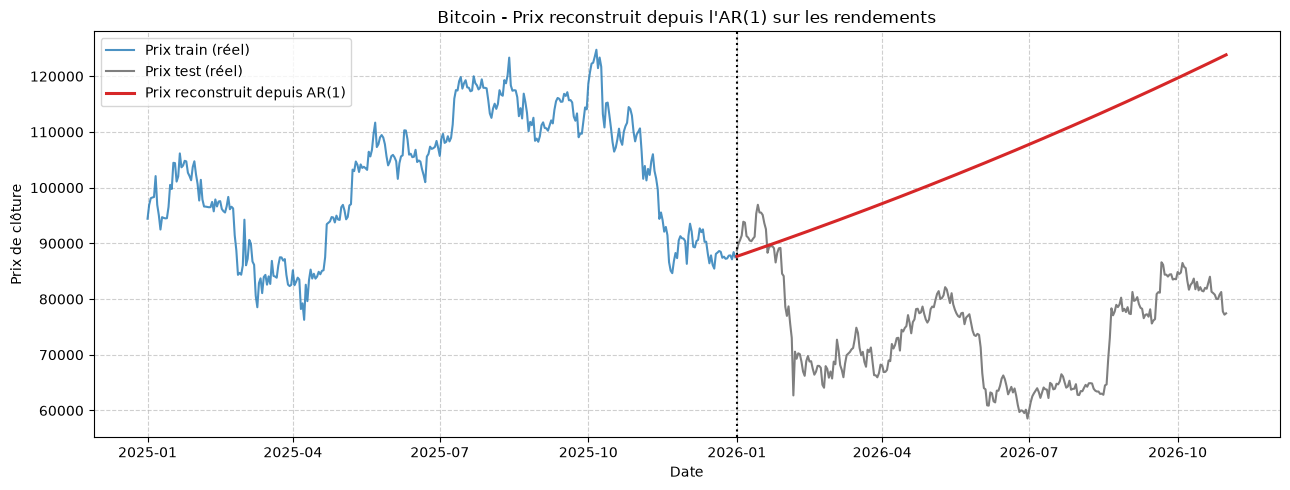

Prix final prévu : 123,844 | Prix final réel : 77,435


In [37]:
ar1_btc.plot_price_from_returns(btc_log, n_train_last=365, title="Bitcoin - Prix reconstruit depuis l'AR(1) sur les rendements")

- **La série est stationnaire** : l'ADF rejette la racine unitaire, et l'AR(1) est bien défini ($|\hat\phi_1| \approx 0.06 \ll 1$).
- $\hat\phi_1 \approx -0.06$ est significatif mais minuscule. La prévision des rendements vaut $\approx 0.18$ % le premier jour, puis retombe en 2 à 3 jours sur $\hat\mu \approx 0.11$ %, car $|e_h| = |\hat\phi_1|^h |e_0|$ est divisé par environ 17 chaque jour.
- **En prix**, un rendement constant de 0.11 %/jour donne une **croissance exponentielle** (≈ +41 % sur 10 mois), qui prolonge la tendance de 2020-2025. Le prix réel a baissé d'environ 11 %. L'AR(1) sur le prix brut (6.4) descendait vers une moyenne sans signification ; l'AR(1) sur les rendements monte selon une tendance passée. Aucun des deux n'utilise d'information réelle sur 2026.

La transformation logarithmique règle donc le problème statistique (stationnarité), mais pas le problème de prévision : **les rendements du BTC sont imprévisibles en moyenne**, et seule leur volatilité présente une structure exploitable (GARCH).

## 7. Un cas où l'AR fonctionne : le VIX

Les parties 3 à 6 montrent que l'AR échoue sur les actions et les cryptos. Ce n'est pas un défaut de l'AR : c'est l'**efficience des marchés**. Un signal dans les rendements passés serait exploité par les arbitragistes jusqu'à disparaître. Nous avons d'ailleurs testé les rendements journaliers d'une trentaine d'actifs Yahoo Finance (petites capitalisations, indices émergents, XRP, DOGE, LTC, XMR, or, pétrole…). Aucun ne garde de structure AR exploitable sur 2026.

Il faut donc une série **stationnaire par nature**, qui **revient vers un niveau moyen**. L'exemple de référence est le **VIX**.

### 7.1. Choix de l'actif et données

**Pourquoi le VIX (`^VIX`) ?**
- Le VIX est l'« indice de la peur » du CBOE. Il mesure la volatilité implicite à 30 jours du S&P 500, déduite des prix des options.
- C'est l'exemple classique de **retour à la moyenne** (*mean reversion*) en finance. Il grimpe brutalement lors des crises (82 en mars 2020), puis redescend toujours vers un niveau « normal » de 15 à 20. Une volatilité ne peut ni croître indéfiniment comme un prix, ni devenir négative.
- Il est donc modélisé, en temps continu, par un processus d'**Ornstein-Uhlenbeck** $dX_t = \kappa(\mu - X_t)\,dt + \sigma\,dW_t$, dont la version discrète est exactement un **AR(1)** : $X_t = \mu + \phi(X_{t-1} - \mu) + \varepsilon_t$ avec $\phi = e^{-\kappa}$.
- On modélise donc directement le **niveau** du VIX, sans transformation (pas de `to_returns()`), contrairement au BTC.

**Horizons** :
- **train** : 2021 → 2025. On démarre après le choc du COVID de 2020, où le VIX est monté jusqu'à 82. Cet épisode extrême aurait dominé l'estimation et gonflé la moyenne.
- **test** : janvier → octobre 2026 (10 mois, comme pour le BTC). Le VIX ne cote que les jours de bourse, d'où environ 210 observations.

In [60]:
vix = DataDownload(ticker="^VIX", start="2021-01-01", end="2026-11-01")
vix.download()
train_vix, test_vix = vix.split(train_end="2025-12-31", test_start="2026-01-01")

DataDownload(ticker='^VIX', start='2021-01-01', end='2026-11-01', n_obs=1466)
Train : 1255 obs. (2021-01-04 → 2025-12-31)
Test  : 211 obs. (2026-01-02 → 2026-10-30)


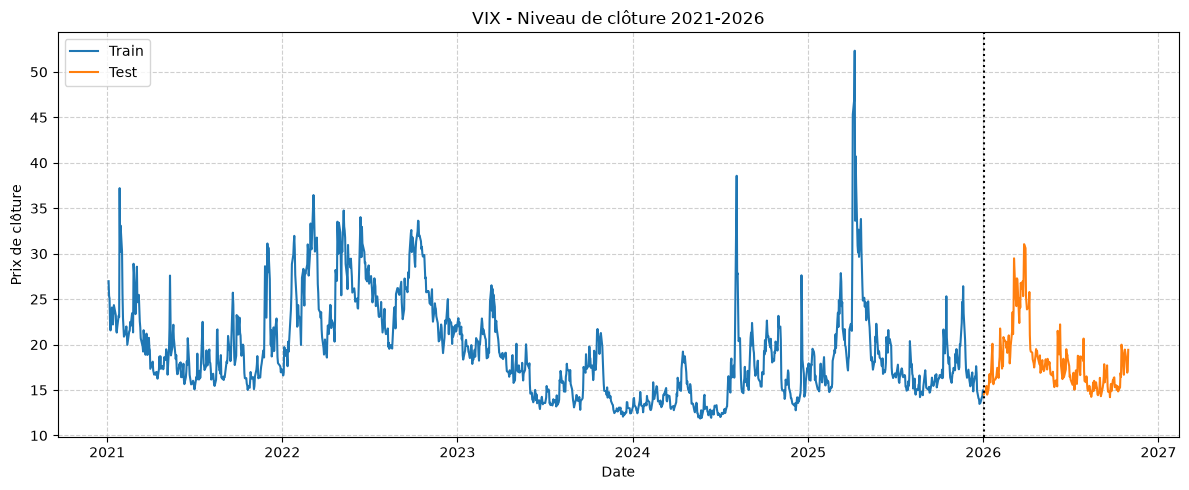

In [61]:
vix.plot(title="VIX - Niveau de clôture 2021-2026")

In [62]:
vix.adf_test()

ADF sur Prix de clôture : stationnaire (H0 rejetée) au seuil de 5 %


,ADF
Statistique ADF,-5.6798
p-valeur,0.0000
Lags utilisés,1.0000
Valeur critique 5 %,-2.8638


Le VIX oscille autour d'environ 19, avec des pics vite résorbés (≈ 52 en août 2024, ≈ 31 en 2026). Contrairement au prix du BTC (p ≈ 0.73), l'ADF **rejette nettement la racine unitaire** (p ≈ 0) : la série est stationnaire, et l'hypothèse de base de l'AR est respectée.

### 7.2. Sélection de modèle

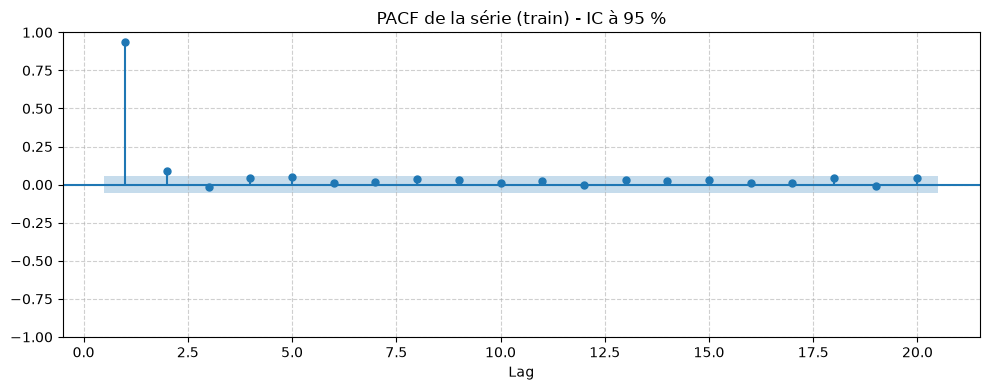

Lags significatifs (hors IC 95 %) : [1, 2]


In [63]:
ar_vix = AR(train_vix, test_vix)
lags_vix = ar_vix.plot_pacf(nlags=20)

In [64]:
ar_vix.select(orders=range(0, 11), criterion="bic")

Meilleur selon l'AIC : AR(2)
Meilleur selon le BIC : AR(2)
-> Modèle retenu (BIC) : AR(2)


,AIC,BIC
Modèle,,
AR(0),7745.43,7755.70
AR(1),5066.80,5082.20
AR(2),5059.19,5079.73
AR(3),5060.79,5086.46
AR(4),5060.80,5091.60
AR(5),5059.33,5095.28
AR(6),5061.04,5102.12
AR(7),5062.56,5108.77
AR(8),5062.79,5114.13


La PACF a un pic très fort au lag 1, un plus faible au lag 2, puis presque plus rien : c'est la signature d'un AR d'ordre faible. **L'AIC et le BIC s'accordent sur l'AR(2).**

### 7.3. Modèle sélectionné

In [65]:
ar_vix.summary()

Modèle retenu : AR(2)
  X_t = 1.0703 + 0.8574 X_(t-1) + 0.0874 X_(t-2) + eps_t,   eps_t ~ BB(0, 3.2715)
  Moyenne mu = 19.3876
  Écart-type du bruit sigma = 1.8087



,Estimation,Écart-type,p-valeur
mu (const),19.3876,1.2767,0.0
phi_1,0.8574,0.0117,0.0
phi_2,0.0874,0.0131,0.0
sigma2,3.2715,0.0473,0.0


In [66]:
ar_vix.roots()

,Polynôme,Racine,Module
0,AR Phi(z),1.0532,1.0532
1,AR Phi(z),-10.8657,10.8657


$$X_t = c + \hat\phi_1 X_{t-1} + \hat\phi_2 X_{t-2} + \varepsilon_t, \qquad \hat\phi_1 \approx 0.86,\ \hat\phi_2 \approx 0.09$$

- **Tous les coefficients sont très significatifs**, et $\hat\mu \approx 19.4$ correspond bien au niveau « normal » du VIX. Cette fois, $\mu$ a un sens économique, contrairement aux 47 000 \$ du BTC.
- **Persistance forte mais stationnaire** : $\hat\phi_1 + \hat\phi_2 \approx 0.945 < 1$. Les deux racines de $\Phi$ sont de module $> 1$ (≈ 1.05 et ≈ 10.9).
- **Vitesse de retour à la moyenne** : la racine dominante donne $\rho = 1/1.053 \approx 0.95$ par jour. La demi-vie vaut $\ln 2 / |\ln\rho| \approx 13$ jours de bourse : un choc sur le VIX se résorbe de moitié en environ 3 semaines.

### 7.4. Prédictions

In [67]:
ar_vix.forecast().iloc[[0, 1, 4, 9, 19, 59, -1]]

,Prévision,IC_inf,IC_sup
Date,,,
2026-01-02 00:00:00-06:00,15.140799,11.595781,18.685817
2026-01-05 00:00:00-06:00,15.358569,10.688876,20.028262
2026-01-08 00:00:00-06:00,15.938993,9.241609,22.636377
2026-01-15 00:00:00-06:00,16.726877,8.337104,25.116650
2026-01-30 00:00:00-06:00,17.803759,8.075704,27.531815
2026-03-30 00:00:00-05:00,19.188738,8.809326,29.568149
2026-10-30 00:00:00-05:00,19.387525,8.998013,29.777038


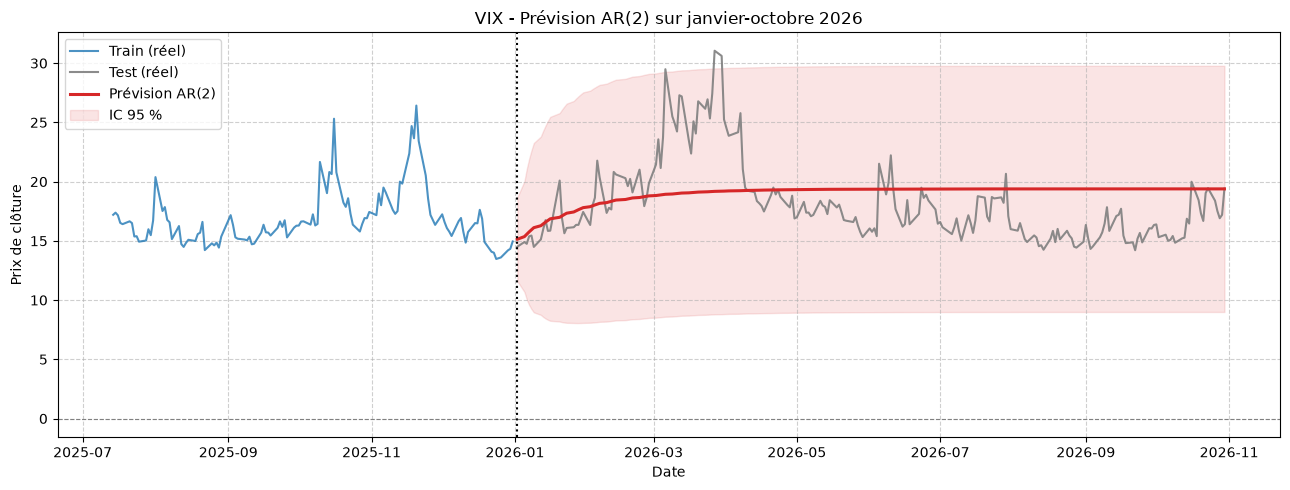

In [68]:
ar_vix.plot_forecast(n_train_last=120, title="VIX - Prévision AR(2) sur janvier-octobre 2026")

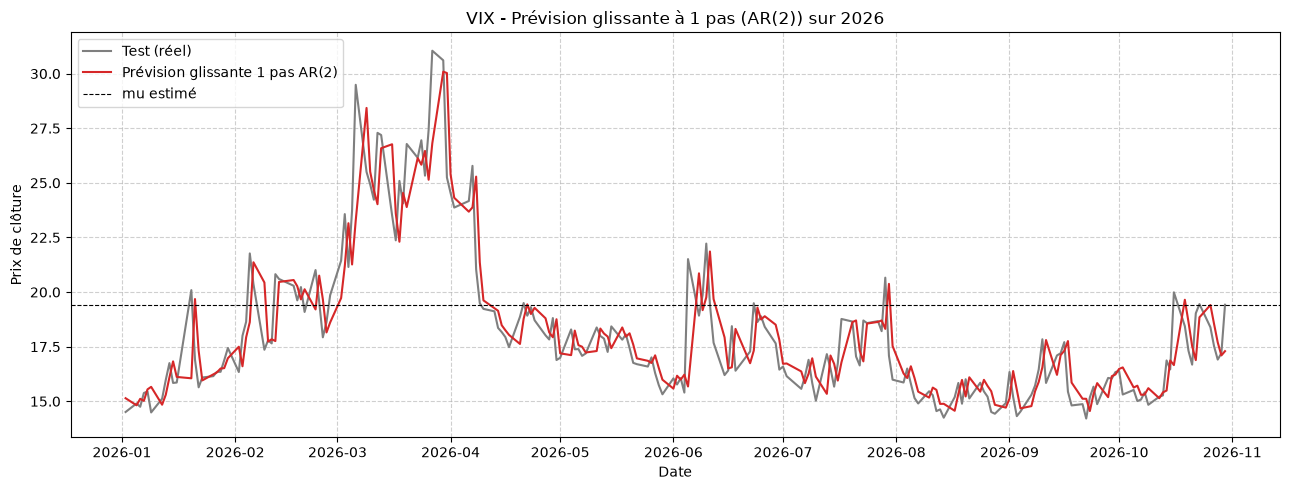

In [69]:
ar_vix.plot_rolling(title="VIX - Prévision glissante à 1 pas (AR(2)) sur 2026")

### 7.5. Résultats

In [70]:
ar_vix.evaluate()

,AR(2)
RMSE,3.4710
MAE,2.7699
Couverture IC 95 % (%),98.5782
Prévision min,15.1408
Prévision max,19.3875
Écart-type de la prévision,0.8434
Moyenne empirique du train,19.3434


In [71]:
ar_vix.compare_naive()

,AR(2),Naïf (dernière valeur)
RMSE,3.47,4.58
MAE,2.77,3.21
Prévision finale,19.39,14.95
Valeur réelle finale,19.42,19.42


In [72]:
ar_vix.rolling_forecast()

,AR(2) glissant 1 pas,Constante mu,Naïf (veille)
RMSE,1.4599,3.5564,1.5029
Bon sens de variation (%),56.3981,56.3981,NaN


**1. La prévision a un vrai contenu.** Fin 2025, le VIX était bas (≈ 15). L'AR(2) prévoit une **remontée progressive vers $\hat\mu \approx 19.4$** : ≈ 16.7 après 10 jours, ≈ 17.8 après 20 jours, ≈ 19.2 après 3 mois. C'est toujours la convergence démontrée en 3.4 ($e_h \to 0$ au taux $\rho^h$), mais elle **décrit maintenant un phénomène réel**, le retour de la volatilité vers son niveau normal. La prévision à 10 mois (≈ 19.39) est quasiment égale à la valeur réalisée fin octobre 2026 (≈ 19.42).

**2. L'AR bat les prédicteurs de référence :**

| | Horizon 10 mois (RMSE / MAE) | Glissant 1 pas (RMSE) |
|---|---|---|
| **AR(2)** | **≈ 3.47 / 2.77** | **≈ 1.46** |
| Naïf (dernière valeur / veille) | ≈ 4.58 / 3.21 | ≈ 1.50 |
| Constante $\mu$ | — | ≈ 3.56 |

- **À 10 mois**, l'AR réduit l'erreur d'environ 25 % par rapport à la marche aléatoire. Parier sur le retour à la moyenne est plus juste que parier sur la persistance du niveau actuel. C'est la différence fondamentale avec le BTC, où le naïf était quasiment imbattable à 1 pas.
- **À 1 pas**, le gain sur la veille est faible (≈ 3 %) mais systématique. Il est logique : avec $\rho \approx 0.95$, le VIX de demain est surtout celui d'aujourd'hui, légèrement tiré vers $\mu$.
- L'IC à 95 % couvre environ 99 % des observations : il est cohérent, plutôt prudent.

**3. Limites.**
- L'AR ne prévoit **pas les pics** (le VIX à ≈ 31 en 2026) : ce sont des chocs imprévisibles $\varepsilon_t$. Il prévoit seulement leur **résorption** une fois qu'ils ont eu lieu.
- La variance des chocs n'est pas constante : les hausses du VIX sont brutales et les baisses lentes (asymétrie), ce qui appellerait un modèle à variance conditionnelle.
- **Le VIX n'est pas achetable directement.** Les produits qui le répliquent (futures, ETN comme `VXX`) intègrent déjà ce retour à la moyenne dans leurs prix : la prévisibilité du VIX n'est donc pas une opportunité d'arbitrage. Les rendements de `VXX` n'avaient d'ailleurs aucune structure AR dans notre scan.

**Conclusion.** L'AR fonctionne quand la série est **stationnaire par nature** et qu'un **mécanisme de retour à la moyenne** existe : c'est le cas de la volatilité (VIX), mais pas des prix ou des rendements d'actions et de cryptos. Le choix du modèle doit partir de la nature de la série, pas seulement des critères statistiques. Enfin, le fait que la **volatilité** soit prévisible alors que les rendements ne le sont pas est précisément l'idée qui fonde les modèles **GARCH**.